# OCR baseline — kimhannom API (Giai đoạn 2)

**Pipeline đơn giản cho baseline:**

```
PDF (_updated.pdf / raw) → pages/*.jpg → kimhannom (upload → image-ocr)
    → boxes + thứ tự đọc → per-page txt → PPOCRLabel export (Label.txt / fileState.txt)
```

**Chỉ hỗ trợ trang Nôm/Hán** (`ch/`) — `lang_type` của API chỉ có Hán và Nôm,
phần Quốc ngữ (`vi/`) sẽ dùng engine khác ở bước sau.

**Chuẩn bị (1 lần, terminal tại project root):**

```powershell
uv pip install requests
```
(`KIMHANNOM_EMAIL` / `KIMHANNOM_PASSWORD` trong `.env` chỉ để tham khảo —
API không có endpoint login; token phải lấy từ cookie phiên đăng nhập.)

**Nguyên tắc cache:** mọi gọi API đều ghi JSON vào `ocr_cache/`. Chạy lại cell
(chạy nháp, đổi PAGE_RANGE) **không tốn lượt gọi** với trang đã OCR. Đổi
`FORCE_REOCR = True` để bỏ cache.


In [60]:
# ============================================================
# CELL 0 — CONFIG & AUTH (kimhannom API baseline)
# ============================================================
import json
import re
import sys
import time
import unicodedata
from pathlib import Path

import requests


def nfc(s: str) -> str:
    """Chuẩn hóa tên file về Unicode NFC (nguy cơ NFC/NFD với tên tiếng Việt)."""
    return unicodedata.normalize("NFC", s)


def find_project_root() -> Path:
    for p in [Path.cwd(), *Path.cwd().parents]:
        if (p / "data" / "raw").is_dir():
            return p
    raise RuntimeError("Không tìm thấy project root (thư mục chứa data/raw/)")


PROJECT_ROOT = find_project_root()
DATA_RAW = PROJECT_ROOT / "data" / "raw"
OUTPUTS = PROJECT_ROOT / "outputs"

# ------------------------------------------------------------
# BOOK đang chạy — đổi đây khi chạy sách khác rồi Restart & Run All
# ------------------------------------------------------------
BOOK = "Ca Trù Thê Cách, AB 160, Nôm_Y.pdf"
BOOK_PATH = next((p for p in DATA_RAW.glob("*.pdf")
                  if nfc(p.stem) == nfc(Path(BOOK).stem)), None)
if BOOK_PATH is None:
    raise FileNotFoundError(f"'{BOOK}' không có trong {DATA_RAW}")
BOOK_STEM = nfc(BOOK_PATH.stem)
BOOK_DIR = OUTPUTS / BOOK_STEM
PAGES_DIR = BOOK_DIR / "pages"
UPDATED_PDF = BOOK_DIR / f"{BOOK_STEM}_updated.pdf"

# ------------------------------------------------------------
# Tham số API image-ocr (theo API docs)
#   ocr_id            : 1 thông thường dọc | 2 hành chính | 3 ngoại cảnh | 4 thông thường ngang
#   lang_type         : 0 tự động | 1 Hán | 2 Nôm   (KHÔNG hỗ trợ Quốc ngữ)
#   reading_direction : 1 dọc (mặc định) | 2 ngang
#   epitaph           : 0 văn bản thường | 1 văn bia
#   tag               : model_id chuyên biệt (null nếu chưa được cấp)
# ------------------------------------------------------------
# Hướng chữ theo từng sách: 1 = Nôm cột dọc (mặc định, đa số sách) | 4 = hàng ngang (T2b)
BOOK_OCR_ID = {
    "Ca Trù Thê Cách, AB 160, Nôm_Y": 1,  # Mặc định, Nôm cột dọc
    "Nhi thap tu hieu dien ca digcoll_35504_Y": 1,  # Mặc định, Nôm cột dọc
    "Tho Ho Xuan Huong [chu nom]": 4,    # T2b, Nôm hàng ngang (theo preprocessing.ipynb)
}
OCR_ID = BOOK_OCR_ID.get(BOOK_STEM, 1)
LANG_TYPE = 2         # Nôm
EPITAPH = 0
OCR_TAG = None
READING_DIRECTION = 2 if OCR_ID == 4 else 1
VERTICAL = READING_DIRECTION == 1   # True = cột dọc phải→trái; False = hàng ngang trái→phải

# ------------------------------------------------------------
# Phạm vi chạy — (trang đầu, trang cuối) theo .001.jpg; None = cả sách
# ------------------------------------------------------------
PAGE_RANGE = (1, 8)   # pilot 8 trang; đặt PAGE_RANGE = None để chạy cả sách
FORCE_REOCR = False   # True = gọi lại API kể cả khi có cache JSON
FORCE_UPLOAD = False  # True = upload lại ảnh kể cả khi có cache upload

BASE = "https://kimhannom.fit.hcmus.edu.vn"
EP_UPLOAD = "/api/web/clc-sinonom/image-upload"
EP_OCR = "/api/web/clc-sinonom/image-ocr"

# ------------------------------------------------------------
# Thư mục output
#   ocr_cache/upload/<stem>.NNN.json  — kết quả upload (file_name server)
#   ocr_cache/kimhannom/<stem>.NNN.json — raw response image-ocr
#   ocr/kimhannom/<stem>.NNN.txt     — text theo thứ tự đọc của từng trang
#   ppocr/ (Label.txt, fileState.txt, ch/*.jpg) — export mở bằng PPOCRLabel
# ------------------------------------------------------------
CACHE_DIR = BOOK_DIR / "ocr_cache" / "kimhannom"
UPLOAD_CACHE_DIR = BOOK_DIR / "ocr_cache" / "upload"
TXT_DIR = BOOK_DIR / "ocr" / "kimhannom"
VIZ_DIR = BOOK_DIR / "viz"
PPOCR_DIR = BOOK_DIR / "ppocr"
LABEL_PREFIX = "ch"
for d in (CACHE_DIR, UPLOAD_CACHE_DIR, TXT_DIR, VIZ_DIR, PPOCR_DIR / LABEL_PREFIX):
    d.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# AUTH — token Bearer lấy từ cookie của web kimhannom (file .env)
# ------------------------------------------------------------
ENV = {}
env_path = PROJECT_ROOT / ".env"
if env_path.exists():
    for line in env_path.read_text(encoding="utf-8").splitlines():
        line = line.strip()
        if line and not line.startswith("#") and "=" in line:
            k, v = line.split("=", 1)
            ENV[k.strip()] = v.strip()

# Lấy token bằng cách đăng nhập (KIMHANNOM_EMAIL / KIMHANNOM_PASSWORD trong .env);
# token chỉ giữ trong bộ nhớ, KHÔNG cần (và không ghi) vào .env.
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from core.kimhannom_client import KimHanNomClient

KHN_LOGIN = KimHanNomClient(auto_login=True)
TOKEN = KHN_LOGIN.token or ""
if not TOKEN:
    raise RuntimeError("Đăng nhập thất bại: kiểm tra KIMHANNOM_EMAIL / KIMHANNOM_PASSWORD trong .env.")

HEADERS_BASE = {
    # User-Agent BẮT BUỘC, KHÔNG được có tiền tố "python-requests" (theo API docs)
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 "
                  "(KHTML, like Gecko) Chrome/126.0 Safari/537.36",
    "Authorization": f"Bearer {TOKEN}",
    "Cookie": f"token={TOKEN}",
}

print(f"Python           : {sys.version.split()[0]}")
print(f"PROJECT_ROOT     : {PROJECT_ROOT}")
print(f"BOOK             : {BOOK_PATH.name}")
print(f"OCR params       : ocr_id={OCR_ID} lang_type={LANG_TYPE} "
      f"reading_direction={READING_DIRECTION} epitaph={EPITAPH} tag={OCR_TAG}")
print(f"Chiều đọc Nôm    : {'cột dọc (phải→trái)' if VERTICAL else 'hàng ngang (trái→phải)'}")
print(f"PAGE_RANGE       : {PAGE_RANGE or 'cả sách'}")
print(f"Token            : {TOKEN[:8]}… (lấy qua đăng nhập)")
print(f"Output dir       : {BOOK_DIR}")


Python           : 3.12.13
PROJECT_ROOT     : d:\Personal\Hcmus\CSC15006-Introduction-to-Natural-Language-Processing\sino-vietnamese-ocr
BOOK             : Ca Trù Thê Cách, AB 160, Nôm_Y.pdf
OCR params       : ocr_id=1 lang_type=2 reading_direction=1 epitaph=0 tag=None
Chiều đọc Nôm    : cột dọc (phải→trái)
PAGE_RANGE       : (1, 8)
Token            : eyJhbGci… (lấy qua đăng nhập)
Output dir       : d:\Personal\Hcmus\CSC15006-Introduction-to-Natural-Language-Processing\sino-vietnamese-ocr\outputs\Ca Trù Thê Cách, AB 160, Nôm_Y


## CELL 1 — Danh sách ảnh Nôm từ `ch/`

Chỉ OCR ảnh trong `ch/` (đã phân loại ở preprocessing.ipynb, gồm cả trang T2b copy sang cả `ch/` và `vi/`). Intro/ref/toc/blank/misc và trang chỉ có ở `vi/` bị bỏ qua — API chỉ hỗ trợ Hán/Nôm.

`PAGE_RANGE` lọc theo số trang trong tên file (`.NNN.jpg`), không phải vị trí trong danh sách.

In [61]:
# ============================================================
# CELL 1 — DANH SÁCH ẢNH NÔM TỪ ch/ ĐỂ OCR
# ============================================================
from PIL import Image

CH_DIR = BOOK_DIR / "ch"


def parse_pno(name: str):
    m = re.search(r"\.(\d{3})\.jpg$", nfc(name))
    return int(m.group(1)) if m else None


if not CH_DIR.is_dir() or not any(CH_DIR.glob("*.jpg")):
    raise RuntimeError(f"{CH_DIR} trống/không tồn tại — chạy preprocessing.ipynb "
                       "(Cell 5: apply classification) để copy trang Nôm vào ch/.")

WORKLIST: list[tuple[int, str, str, Path]] = []   # (pno, filename, side, path)
for jpg in sorted(CH_DIR.glob("*.jpg")):
    pno = parse_pno(jpg.name)
    if pno is None:
        continue
    if PAGE_RANGE:
        lo, hi = PAGE_RANGE
        if pno < lo or (hi is not None and pno > hi):
            continue
    WORKLIST.append((pno, nfc(jpg.name), "ch", jpg))
WORKLIST.sort()

IMG_SIZE: dict[int, tuple[int, int]] = {}
for pno, _name, _side, jpg in WORKLIST:
    try:
        IMG_SIZE[pno] = Image.open(jpg).size          # (w, h)
    except Exception as e:
        print(f"⚠️  p{pno:03d} không mở được ảnh: {e}")

if not WORKLIST:
    raise RuntimeError(f"WORKLIST trống — không có ảnh nào trong {CH_DIR.name}/ "
                       f"thuộc PAGE_RANGE={PAGE_RANGE}")
print(f"ch/              : {len(list(CH_DIR.glob('*.jpg')))} file")
print(f"WORKLIST (OCR)   : {len(WORKLIST)} trang, pno {WORKLIST[0][0]:03d}…{WORKLIST[-1][0]:03d}")
print("pno | file")
for pno, name, _side, _jpg in WORKLIST:
    print(f" {pno:03d}| {name}")


ch/              : 43 file
WORKLIST (OCR)   : 7 trang, pno 001…008
pno | file
 001| Ca Trù Thê Cách, AB 160, Nôm_Y.001.jpg
 002| Ca Trù Thê Cách, AB 160, Nôm_Y.002.jpg
 003| Ca Trù Thê Cách, AB 160, Nôm_Y.003.jpg
 005| Ca Trù Thê Cách, AB 160, Nôm_Y.005.jpg
 006| Ca Trù Thê Cách, AB 160, Nôm_Y.006.jpg
 007| Ca Trù Thê Cách, AB 160, Nôm_Y.007.jpg
 008| Ca Trù Thê Cách, AB 160, Nôm_Y.008.jpg


## CELL 2 — API client (upload → image-ocr) + cache + retry

Đối chiếu chuẩn response `{is_success, code, message, data}` — `code == "000000"`
là thành công. Mọi response đều ghi vào `ocr_cache/` để chạy lại không tốn lượt gọi.

In [62]:
# ============================================================
# CELL 2 — API CLIENT: upload_page / ocr_page (+cache, +retry)
# ============================================================
AUTH_FAIL_HINT = ("401 → token hết hạn hoặc chưa đúng. Đăng nhập lại web kimhannom, "
                  "copy cookie 'token' mới vào .env rồi Restart & Run All.")


def check(resp):
    """Validate cấu trúc response chuẩn; trả về data."""
    if not isinstance(resp, dict) or "is_success" not in resp:
        raise RuntimeError(f"Response không đúng schema: {str(resp)[:200]}")
    if not resp.get("is_success") or resp.get("code") != "000000":
        raise RuntimeError(f"API error code={resp.get('code')} "
                           f"message={json.dumps(resp.get('message'), ensure_ascii=False)}")
    return resp.get("data")


def api_call(url: str, *, payload=None, files=None, timeout=300):
    """POST kèm retry 3 lần (429/5xx/network); lỗi 401 báo ngay (token)."""
    last_err = None
    for attempt in range(1, 4):
        try:
            r = requests.post(BASE + url, json=payload, files=files,
                              headers=HEADERS_BASE, timeout=timeout)
            if r.status_code == 401:
                raise RuntimeError(AUTH_FAIL_HINT)
            r.raise_for_status()
            return r.json()
        except RuntimeError:
            raise
        except Exception as e:
            last_err = e
            print(f"  [retry {attempt}/3] {url}: {type(e).__name__}: {e}")
            time.sleep(3 * attempt)
    raise RuntimeError(f"API {url} lỗi 3 lần liên tiếp: {last_err}")


def upload_page(jpg_path: Path, force: bool = False) -> str:
    """Upload ảnh → file_name server (cache theo tên trang)."""
    cache = UPLOAD_CACHE_DIR / f"{jpg_path.stem}.json"
    if cache.exists() and not force:
        return json.loads(cache.read_text(encoding="utf-8"))["file_name"]
    with open(jpg_path, "rb") as f:
        files = {"image_file": (nfc(jpg_path.name), f, "image/jpeg")}
        resp = api_call(EP_UPLOAD, files=files, timeout=120)
    file_name = check(resp)["file_name"]
    cache.write_text(json.dumps({"file_name": file_name}, ensure_ascii=False),
                     encoding="utf-8")
    return file_name


def ocr_page(jpg_path: Path, file_name: str):
    """image-ocr → record. Trả về (record, cache_hit).
    Cache chỉ dùng khi tham số OCR (ocr_id, lang_type, reading_direction, ...)
    trùng với lần gọi trước — đổi tham số sẽ tự gọi lại API."""
    cache = CACHE_DIR / f"{jpg_path.stem}.json"
    request = {
        "ocr_id": OCR_ID,
        "lang_type": LANG_TYPE,
        "reading_direction": READING_DIRECTION,   # 1 dọc | 2 ngang (mặc định API = dọc!)
        "epitaph": EPITAPH,
        "tag": OCR_TAG,
        "file_name": file_name,
    }
    if cache.exists() and not FORCE_REOCR:
        rec = json.loads(cache.read_text(encoding="utf-8"))
        old = {k: v for k, v in (rec.get("request") or {}).items() if k != "file_name"}
        new = {k: v for k, v in request.items() if k != "file_name"}
        if old == new:
            return rec, True
        print(f"  (cache cũ dùng tham số khác {old} → OCR lại)")
    resp = api_call(EP_OCR, payload=request)
    check(resp)
    record = {"request": request, "response": resp, "ts": time.strftime("%Y-%m-%d %H:%M:%S")}
    cache.write_text(json.dumps(record, ensure_ascii=False, indent=1), encoding="utf-8")
    return record, False


print("API client sẵn sàng.")


API client sẵn sàng.


In [63]:
# ============================================================
# CELL 3 — CHẠY OCR BATCH (upload + image-ocr cho từng trang)
# Output: RESULTS[pno] = record cache của trang đó
# Trang lỗi được in ra nhưng KHÔNG dừng batch — chạy lại cell là bù phần thiếu
# (các trang OK đã cache, không tốn thêm lượt gọi).
# ============================================================
RESULTS: dict[int, dict] = {}
FAILURES: list[tuple[int, str]] = []
t0 = time.time()

for i, (pno, name, side, jpg) in enumerate(WORKLIST, 1):
    print(f"[{i:>3}/{len(WORKLIST)}] p{pno:03d} {name} ({side}) ", end="", flush=True)
    try:
        file_name = upload_page(jpg, force=FORCE_UPLOAD)
        rec, hit = ocr_page(jpg, file_name)
        RESULTS[pno] = rec
        data = (rec.get("response") or {}).get("data") or {}
        n_txt = len(data.get("result_ocr_text") or [])
        n_box = len(data.get("result_bbox") or [])
        print(f"→ {'cache' if hit else 'OCR'}  text={n_txt} bbox={n_box}  ({time.time() - t0:.0f}s)")
        time.sleep(1.0)                      # lịch sự với server giữa các trang
    except Exception as e:
        FAILURES.append((pno, f"{type(e).__name__}: {e}"))
        print(f"→ ✗ FAIL: {e}")

n_ok = len(RESULTS)
print(f"\nXong: OK {n_ok}/{len(WORKLIST)} trang" + ("" if not FAILURES else f", FAIL {len(FAILURES)}"))
if FAILURES:
    for pno, err in FAILURES:
        print(f"  ✗ p{pno:03d}  {err}")
    print("→ Chạy lại cell này (trang OK đã cache) để bù trang fail.")


[  1/7] p001 Ca Trù Thê Cách, AB 160, Nôm_Y.001.jpg (ch) → OCR  text=13 bbox=13  (8s)
[  2/7] p002 Ca Trù Thê Cách, AB 160, Nôm_Y.002.jpg (ch) → OCR  text=2 bbox=2  (12s)
[  3/7] p003 Ca Trù Thê Cách, AB 160, Nôm_Y.003.jpg (ch) → OCR  text=1 bbox=1  (18s)
[  4/7] p005 Ca Trù Thê Cách, AB 160, Nôm_Y.005.jpg (ch) → OCR  text=6 bbox=6  (24s)
[  5/7] p006 Ca Trù Thê Cách, AB 160, Nôm_Y.006.jpg (ch) → OCR  text=31 bbox=31  (34s)
[  6/7] p007 Ca Trù Thê Cách, AB 160, Nôm_Y.007.jpg (ch) → OCR  text=23 bbox=23  (48s)
[  7/7] p008 Ca Trù Thê Cách, AB 160, Nôm_Y.008.jpg (ch) → OCR  text=47 bbox=47  (62s)

Xong: OK 7/7 trang


## CELL 4 — Parse response → boxes + thứ tự đọc

`data` có `result_ocr_text` (list text) và `result_bbox` — phần sau **có thể rỗng**
(như ví dụ trong API docs), và schema bbox docs chưa mô tả tỉ mỉ. Cell này đọc
phòng thủ: 2 điểm góc / 4 điểm / 8 số / toạ độ chuẩn hoá 0–1, đồng thời in một
mẫu response để bạn đối chiếu schema thực tế.

Nếu `result_bbox` rỗng (hoặc thiếu) → gộp cả trang thành 1 box: đủ dùng cho
export PPOCRLabel baseline; nâng cấp sau bằng `layout-detection` / `draw-layout`.

In [64]:
# ============================================================
# CELL 4 — PARSE RESPONSE → ITEMS (bbox 4 điểm + text) + THỨ TỰ ĐỌC
# ============================================================
def normalize_bbox(raw, img_w, img_h):
    """Trả về 4 điểm góc int [[x1,y1],[x2,y1],[x2,y2],[x1,y2]] hoặc None.
    Phòng thủ: chấp nhận 2 góc (x1,y1,x2,y2) / 8 số / toạ độ chuẩn hoá 0–1."""
    if raw is None:
        return None
    if isinstance(raw, dict):
        raw = [raw.get(k, 0) for k in ("x1", "y1", "x2", "y2")]
    try:
        nums = [float(v) for v in raw]
    except (TypeError, ValueError):
        return None
    if not nums:
        return None
    if max(nums) <= 2.0 and img_w > 50:        # toạ độ chuẩn hoá 0..1 → đổi sang px
        nums = [(v * img_w if i % 2 == 0 else v * img_h) for i, v in enumerate(nums)]
    if len(nums) == 4:                          # x1, y1, x2, y2
        x1, y1, x2, y2 = nums
        return [[int(min(x1, x2)), int(min(y1, y2))],
                [int(max(x1, x2)), int(min(y1, y2))],
                [int(max(x1, x2)), int(max(y1, y2))],
                [int(min(x1, x2)), int(max(y1, y2))]]
    if len(nums) == 8:                          # 4 điểm bất kỳ
        pts = [[int(nums[i]), int(nums[i + 1])] for i in range(0, 8, 2)]
        xs = [p[0] for p in pts]
        ys = [p[1] for p in pts]
        return [[min(xs), min(ys)], [max(xs), min(ys)],
                [max(xs), max(ys)], [min(xs), max(ys)]]
    return None


def xy(b):
    xs = [p[0] for p in b]
    ys = [p[1] for p in b]
    return min(xs), min(ys), max(xs), max(ys)


def make_items(pno: int, rec: dict) -> list:
    """record → items [{bbox, text, score}] (thứ tự như API trả về).
    Ưu tiên data["details"] ({transcription, points}); fallback result_bbox
    (mỗi phần tử = [4 điểm, [text, score]]) rồi tới result_ocr_text."""
    data = (rec.get("response") or {}).get("data") or {}
    w, h = IMG_SIZE.get(pno, (1500, 2000))
    details = (data.get("details") or {}).get("details") or []
    if details:
        rb = data.get("result_bbox") or []
        scores = [e[1][1] if len(e) > 1 and len(e[1]) > 1 else None for e in rb]
        if len(scores) != len(details):
            scores = [None] * len(details)
        return [{"bbox": normalize_bbox(sum(d["points"], []), w, h),
                 "text": str(d.get("transcription", "")), "score": sc}
                for d, sc in zip(details, scores) if d.get("points")]
    items = []
    for ent in data.get("result_bbox") or []:
        try:
            pts, (txt, score) = ent[0], ent[1]
            items.append({"bbox": normalize_bbox(sum(pts, []), w, h),
                          "text": str(txt), "score": float(score)})
        except Exception:
            continue
    if items:
        return items
    # không có bbox → mỗi đoạn text 1 entry không toạ độ (sẽ gộp sau)
    return [{"bbox": None, "text": t, "score": None}
            for t in data.get("result_ocr_text") or []]


def order_items(items: list, vertical: bool) -> list:
    """Thứ tự đọc:
       vertical=True  : cột phải→trái, trong cột trên→dưới
       vertical=False : hàng trên→dưới, trong hàng trái→phải
       Thiếu bbox → giữ nguyên thứ tự API trả về (đã là thứ tự đọc)."""
    boxed = [it for it in items if it["bbox"]]
    if len(boxed) != len(items) or not boxed:
        return items
    boxes = [(xy(it["bbox"]), it) for it in items]
    hs = sorted(c[3] - c[1] for c, _it in boxes)
    thr = 1.0 * hs[len(hs) // 2]                # baseline heuristic — tinh chỉnh sau

    key_main = (lambda c: -c[0]) if vertical else (lambda c: c[1])
    key_sub = (lambda c: c[1]) if vertical else (lambda c: c[0])

    boxes.sort(key=lambda t: key_main(t[0]))
    groups: list[list] = []
    cur_key = None
    for c, it in boxes:
        k = key_main(c)
        if cur_key is None or abs(k - cur_key) > thr:
            groups.append([it])
            cur_key = k
        else:
            groups[-1].append(it)
    for g in groups:
        g.sort(key=lambda it: key_sub(xy(it["bbox"])))
    return [it for g in groups for it in g]


ITEMS: dict[int, list] = {}
for pno, rec in RESULTS.items():
    items = order_items(make_items(pno, rec), VERTICAL)
    if items and all(it["bbox"] is None for it in items):
        joined = "".join(it["text"] for it in items)
        w, h = IMG_SIZE.get(pno, (1500, 2000))
        items = [{"bbox": [[0, 0], [w, 0], [w, h], [0, h]], "text": joined}]
        print(f"⚠️  p{pno:03d}: result_bbox rỗng → gộp cả trang thành 1 box (nâng cấp: layout-detection)")
    ITEMS[pno] = items

# ------------------------------------------------------------
# In mẫu 1 trang để rà schema thực tế của response
# ------------------------------------------------------------
if RESULTS:
    pno = next(iter(RESULTS))
    data_plain = json.dumps((RESULTS[pno].get("response") or {}).get("data"), ensure_ascii=False)
    print(f"Mẫu response data p{pno:03d} (cắt 700 ký tự):")
    print(data_plain[:700])

print("\n pno | items | chars | bbox?")
for pno in sorted(ITEMS):
    items = ITEMS[pno]
    n_char = sum(len(it["text"]) for it in items)
    n_null = sum(1 for it in items if it["bbox"] is None)
    print(f" {pno:03d}| {len(items):>5} | {n_char:>5} | " + ("OK" if not n_null else f"{n_null} thiếu"))


Mẫu response data p001 (cắt 700 ký tự):
{"result_file_name": "temp_26dc8ff0e5134062a63a50e62c8ebe9e.jpg", "result_ocr_text": ["亿", "叶时甜此", "的", "河啡", "日", "品", "只", "白的", "小", "亿", "曰", "口", "之"], "result_bbox": [[[[2274.0, 1035.0], [2325.0, 1035.0], [2325.0, 1087.0], [2274.0, 1087.0]], ["亿", 0.9803065061569214]], [[[1723.0, 1035.0], [2271.0, 1035.0], [2271.0, 1084.0], [1723.0, 1084.0]], ["叶时甜此", 0.6350623965263367]], [[[1577.0, 1079.0], [1685.0, 1079.0], [1685.0, 1128.0], [1577.0, 1128.0]], ["的", 0.37383800745010376]], [[[1058.0, 612.0], [1269.0, 612.0], [1269.0, 654.0], [1058.0, 654.0]], ["河啡", 0.731419563293457]], [[[1055.0, 712.0], [1130.0, 712.0], [1130.0, 754.0], [1055.0, 754.0]], ["日", 0.8494323492050171]], [[[1053.0, 960.0

 pno | items | chars | bbox?
 001|    13 |    18 | OK
 002|     2 |     5 | OK
 003|     1 |     2 | OK
 005|     6 |    11 | OK
 006|    31 |    93 | OK
 007|    23 |    98 | OK
 008|    47 |    78 | OK


## CELL 4b — Lọc & làm sạch box Nôm

Trang T2b xen kẽ dòng Nôm và dòng Quốc ngữ; OCR Nôm đọc dòng Quốc ngữ thành chuỗi Hán
rác (`唱唱唱`, `山山…`) với confidence thấp. Cell này giữ lại **chỉ box Nôm thật**:

1. Bỏ box **confidence thấp** (`MIN_SCORE`) — dòng Quốc ngữ bị đọc nhầm.
2. Bỏ box **rác lặp** (một chữ lặp ≥ 3 lần liên tiếp / chỉ 1–2 ký tự lạ) và box **không có ký tự CJK**.
3. Bỏ **số trang / header / footer** (chỉ chữ số, hoặc nằm dải trên/dưới cùng và rất ngắn).
4. Bỏ box **trùng** (IoU > 0.5, giữ box confidence cao hơn).
5. **Làm sạch text**: NFC, bỏ khoảng trắng, dấu câu → toàn giác (`、。！？；：`).

Box bị loại ghi vào `DROPPED` và `ocr/dropped_boxes.csv` để rà lại — chỉnh `MIN_SCORE`
nếu thấy mất dòng Nôm thật (hoặc còn sót dòng Quốc ngữ).

In [65]:
# ============================================================
# CELL 4b — LỌC & LÀM SẠCH BOX NÔM (cập nhật ITEMS tại chỗ)
# ============================================================
import csv

MIN_SCORE = 0.75          # dòng Nôm thật ≥ ~0.8; dòng Quốc ngữ bị đọc nhầm ≤ ~0.68
MIN_SCORE_SHORT = 0.8     # box ≤ 2 ký tự phải chắc chắn hơn
BAND = 0.04               # dải trên/dưới (tỉ lệ chiều cao) xét header/footer/số trang
DUP_IOU = 0.5
PUNCT_FULLWIDTH = {",": "、", ".": "。", "!": "！", "?": "？", ";": "；", ":": "："}


def is_cjk(ch: str) -> bool:
    cp = ord(ch)
    return (0x3400 <= cp <= 0x4DBF or 0x4E00 <= cp <= 0x9FFF or 0xF900 <= cp <= 0xFAFF
            or 0x20000 <= cp <= 0x3134F          # Ext B–H (Nôm: 𠊚 𢛨 …)
            or 0xF0000 <= cp <= 0x10FFFF         # PUA (chữ Nôm chưa có Unicode)
            or 0xE000 <= cp <= 0xF8FF)


def clean_nom(text: str) -> str:
    t = unicodedata.normalize("NFC", text)
    t = re.sub(r"\s+", "", t)
    return "".join(PUNCT_FULLWIDTH.get(ch, ch) for ch in t)


def iou(a, b) -> float:
    ax1, ay1, ax2, ay2 = xy(a); bx1, by1, bx2, by2 = xy(b)
    iw, ih = min(ax2, bx2) - max(ax1, bx1), min(ay2, by2) - max(ay1, by1)
    if iw <= 0 or ih <= 0:
        return 0.0
    inter = iw * ih
    return inter / ((ax2 - ax1) * (ay2 - ay1) + (bx2 - bx1) * (by2 - by1) - inter)


def drop_reason(it: dict, page_h: int) -> str | None:
    t = clean_nom(it["text"])
    sc = it.get("score")
    if not t:
        return "empty"
    n_cjk = sum(is_cjk(ch) for ch in t)
    if n_cjk == 0:
        return "no_cjk"
    if re.fullmatch(r"[0-9０-９]+", t):
        return "digits"
    if re.search(r"(.)\1{2,}", t):
        return "repeat_garbage"
    if sc is not None:
        if sc < MIN_SCORE:
            return f"low_score<{MIN_SCORE}"
        if len(t) <= 2 and sc < MIN_SCORE_SHORT:
            return "short_low_score"
    if it["bbox"] and len(t) <= 2:
        _x1, y1, _x2, y2 = xy(it["bbox"])
        if y2 < BAND * page_h or y1 > (1 - BAND) * page_h:
            return "header_footer"
    return None


DROPPED: dict[int, list] = {}
for pno in sorted(ITEMS):
    w, h = IMG_SIZE.get(pno, (1500, 2000))
    kept, dropped = [], []
    for it in ITEMS[pno]:
        why = drop_reason(it, h)
        (dropped.append({**it, "why": why}) if why else kept.append(it))
    # trùng box: giữ box có score cao hơn
    kept.sort(key=lambda it: -(it.get("score") or 0))
    uniq = []
    for it in kept:
        if it["bbox"] and any(u["bbox"] and iou(it["bbox"], u["bbox"]) > DUP_IOU for u in uniq):
            dropped.append({**it, "why": "duplicate"})
        else:
            uniq.append(it)
    # trả lại thứ tự đọc ban đầu
    order = {id(it): i for i, it in enumerate(ITEMS[pno])}
    uniq.sort(key=lambda it: order[id(it)])
    for it in uniq:
        it["text"] = clean_nom(it["text"])
    DROPPED[pno] = dropped
    ITEMS[pno] = uniq

drop_csv = BOOK_DIR / "ocr" / "dropped_boxes.csv"
with open(drop_csv, "w", newline="", encoding="utf-8-sig") as f:
    wr = csv.writer(f)
    wr.writerow(["page", "why", "score", "text", "bbox"])
    for pno, ds in sorted(DROPPED.items()):
        for d in ds:
            wr.writerow([pno, d["why"], d.get("score"), d["text"], d["bbox"]])

print(" pno | giữ | loại | lý do")
for pno in sorted(ITEMS):
    why = {}
    for d in DROPPED[pno]:
        why[d["why"].split("<")[0]] = why.get(d["why"].split("<")[0], 0) + 1
    print(f" {pno:03d} | {len(ITEMS[pno]):>3} | {len(DROPPED[pno]):>4} | {why}")
print(f"Log box bị loại: {drop_csv}")


 pno | giữ | loại | lý do
 001 |   6 |    7 | {'low_score': 7}
 002 |   1 |    1 | {'low_score': 1}
 003 |   0 |    1 | {'low_score': 1}
 005 |   2 |    4 | {'low_score': 4}
 006 |  29 |    2 | {'low_score': 1, 'short_low_score': 1}
 007 |  14 |    9 | {'low_score': 9}
 008 |  33 |   14 | {'low_score': 14}
Log box bị loại: d:\Personal\Hcmus\CSC15006-Introduction-to-Natural-Language-Processing\sino-vietnamese-ocr\outputs\Ca Trù Thê Cách, AB 160, Nôm_Y\ocr\dropped_boxes.csv


p001 overlay: Ca Trù Thê Cách, AB 160, Nôm_Y.001.overlay.jpg (6 boxes)


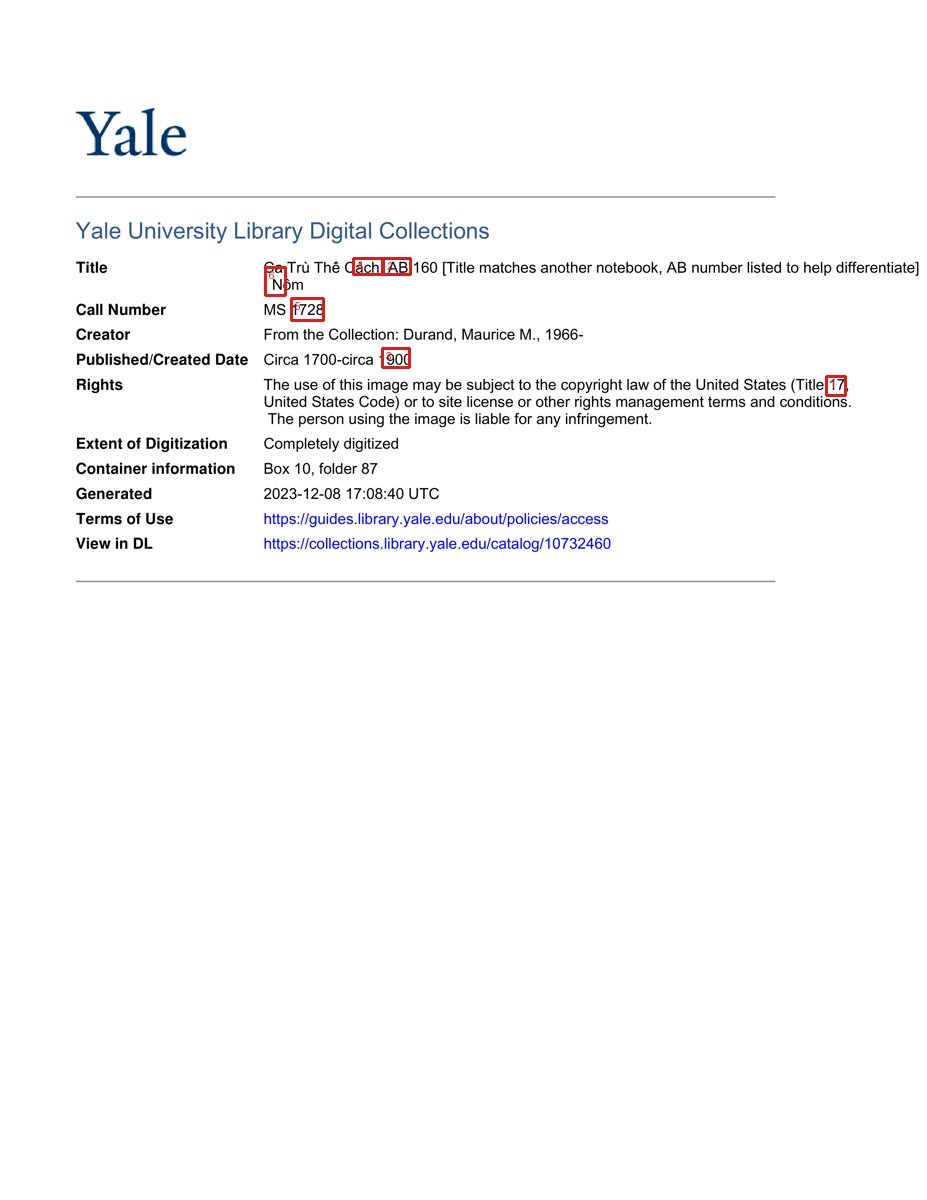

p002 overlay: Ca Trù Thê Cách, AB 160, Nôm_Y.002.overlay.jpg (1 boxes)


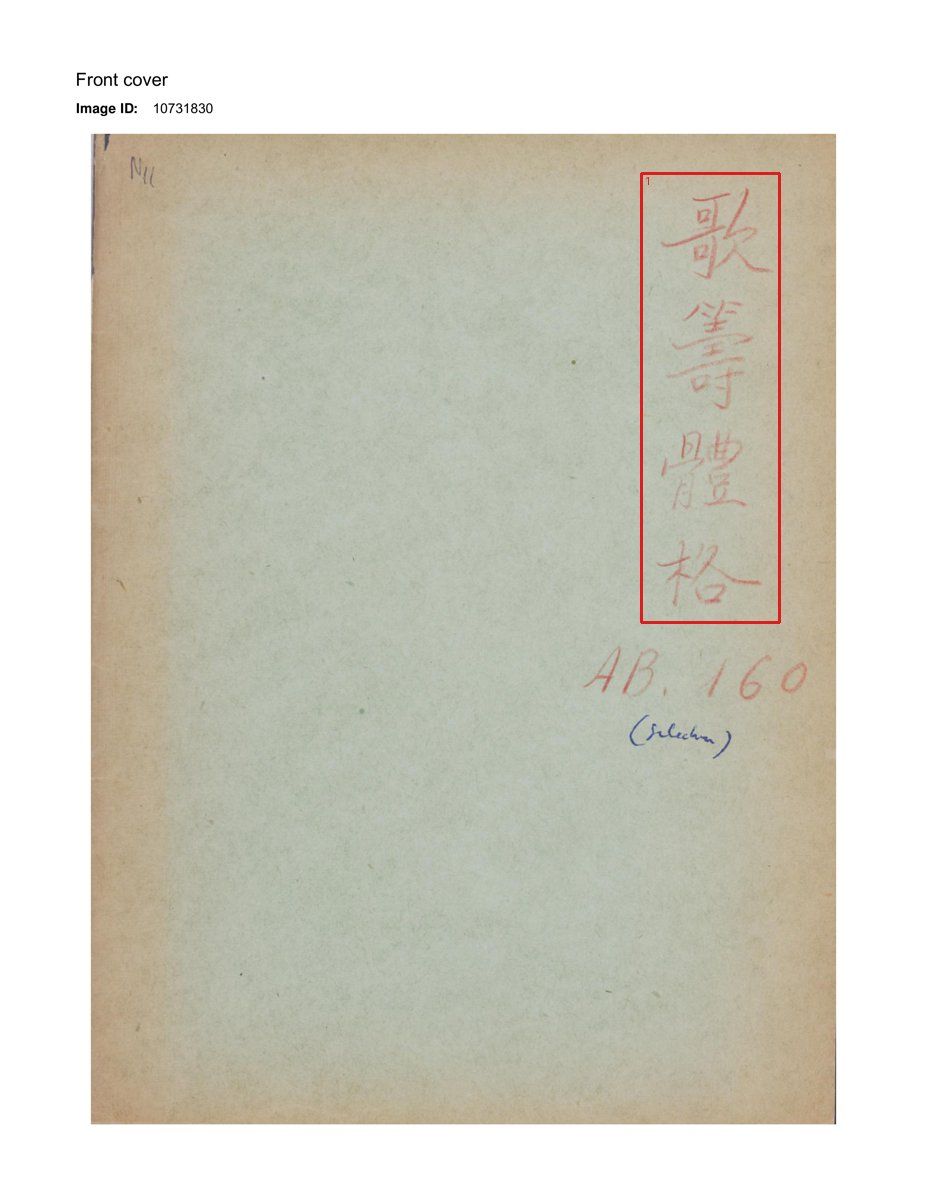

In [66]:
# ============================================================
# CELL 5 — OVERLAY VIZ (rà nhanh boxes cắm lên ảnh gốc)
# ============================================================
from PIL import Image, ImageDraw
from IPython.display import Image as IPyImage, display

N_VIZ = 2   # số trang (có bbox) sẽ hiển thị


def draw_overlay(jpg_path: Path, items: list, out_path: Path) -> Path:
    im = Image.open(jpg_path).convert("RGB")
    w0 = im.width
    im.thumbnail((1200, 1200))
    scale = w0 / im.width
    d = ImageDraw.Draw(im)
    for i, it in enumerate(items, 1):
        if it["bbox"] is None:
            continue
        b = [(int(x / scale), int(y / scale)) for x, y in it["bbox"]]
        d.line(b + [b[0]], fill=(220, 30, 30), width=3)
        d.text((b[0][0] + 4, b[0][1] + 2), str(i), fill=(220, 30, 30))
    im.save(out_path, "JPEG", quality=85)
    return out_path


def n_boxes(pno: int) -> int:
    return sum(1 for it in ITEMS.get(pno, []) if it["bbox"] is not None)


viz_pages = [w for w in WORKLIST if n_boxes(w[0]) > 0][:N_VIZ]
if not viz_pages:
    print("Không có trang nào có bbox > 0 (kiểm tra OCR / bộ lọc CELL 4b).")
for pno, name, side, jpg in viz_pages:
    out = VIZ_DIR / f"{Path(name).stem}.overlay.jpg"
    draw_overlay(jpg, ITEMS[pno], out)
    print(f"p{pno:03d} overlay: {out.name} ({n_boxes(pno)} boxes)")
    display(IPyImage(filename=str(out)))


In [67]:
# ============================================================
# CELL 6 — TEXT THỨ TỰ ĐỌC PER PAGE: ocr/kimhannom/<stem>.NNN.txt
# Nôm không có khoảng trắng giữa các chữ — chuỗi text API trả về ghép nguyên,
# chỉ xoá xuống hàng (1 bản ghi Label.txt phải nằm trên 1 dòng).
# ============================================================
for pno, items in sorted(ITEMS.items()):
    text = "".join(it["text"].replace("\n", " ").strip() for it in items)
    out = TXT_DIR / f"{BOOK_STEM}.{pno:03d}.txt"
    out.write_text(text, encoding="utf-8")
    preview = text[:60] + ("…" if len(text) > 60 else "")
    print(f"p{pno:03d} {len(text):>5} ký tự | {out.name} | {preview}")


p001     7 ký tự | Ca Trù Thê Cách, AB 160, Nôm_Y.001.txt | 亿日品白的亿之
p002     4 ký tự | Ca Trù Thê Cách, AB 160, Nôm_Y.002.txt | 歌籌體格
p003     0 ký tự | Ca Trù Thê Cách, AB 160, Nôm_Y.003.txt | 
p005     2 ký tự | Ca Trù Thê Cách, AB 160, Nôm_Y.005.txt | 格点
p006    91 ký tự | Ca Trù Thê Cách, AB 160, Nôm_Y.006.txt | 中去月留似瓢渃沒𣳔碧似雪年船興禰東白似青如𡥵適似𠤆𤎜運空色似波如里乡隨秋如自襊日𨢇寬聲影𥘀默𠦳𡗶歌臘似𨔾始盡伽意之𦋦翻醉…
p007    82 ký tự | Ca Trù Thê Cách, AB 160, Nôm_Y.007.txt | 雪青如多南遊花如偷染鎻窖𠊚期几心雲咖樹如造逴﨤默河嶺似𡥵致公吏餘情似宦旦初閒𨢇咾如酒書滌𣈜供雜𠓨吏景勝閒名了詩簿𦓡洮品傘…
p008    59 ký tự | Ca Trù Thê Cách, AB 160, Nôm_Y.008.txt | 俗世始烟𫅷歌覺樂如知念貝渚世北酒何便酒誰醒恊歌又唭𡽫𠹳払渃生在惟幾仙能一時後固衣吀人情貴夢及身鿄不似年𦝄慢拱最黄縱百点


## CELL 7 — Export PPOCRLabel

Copy ảnh đã OCR vào `ppocr/ch/` và viết:

- `ppocr/Label.txt` — mỗi dòng: `ch/<tên>.jpg<TAB>[{transcription, points, difficult}]`
  (points = **đúng 4 điểm góc int**; transcription chỉ 1 dòng)
- `ppocr/fileState.txt` — cùng đường dẫn + `<TAB>1` (đã xác nhận)

Mở `outputs/<Tên sách>/ppocr/` bằng PPOCRLabel để xem/sửa box. Sau khi sửa tay
trong PPOCRLabel, `Label.txt` là **source of truth** — cell này **không ghi đè**
Label.txt đã tồn tại (muốn sinh lại phải xoá file cũ).

In [68]:
# ============================================================
# CELL 7 — EXPORT PPOCRLabel (Label.txt + fileState.txt + ch/*.jpg)
# ============================================================
import shutil

LABEL_PATH = PPOCR_DIR / "Label.txt"
STATE_PATH = PPOCR_DIR / "fileState.txt"

# Không ghi đè Label.txt đã tồn tại (có thể đã sửa tay trong PPOCRLabel)
if LABEL_PATH.exists():
    print("⛔ Label.txt đã tồn tại — không đè (đây là bản đã sửa tay, giữ nguyên).")
    print("   Muốn sinh lại từ cache: xoá Label.txt + fileState.txt rồi chạy lại cell.")
else:
    label_lines: list[str] = []
    state_lines: list[str] = []
    n_box_total = 0

    for pno, name, _side, jpg in WORKLIST:
        if pno not in ITEMS or not ITEMS[pno]:
            continue
        shutil.copy2(jpg, PPOCR_DIR / LABEL_PREFIX / name)

        entries = []
        for it in ITEMS[pno]:
            trans = it["text"].replace("\n", " ").strip()
            if not trans:
                continue
            pts = it["bbox"]
            if pts is None:                    # không có bbox → box cả trang
                w, h = IMG_SIZE.get(pno, (1500, 2000))
                pts = [[0, 0], [w, 0], [w, h], [0, h]]
            entries.append({"transcription": trans, "points": pts, "difficult": False})

        if not entries:
            continue
        rel = f"{LABEL_PREFIX}/{name}"
        label_lines.append(f"{rel}\t{json.dumps(entries, ensure_ascii=False)}")
        state_lines.append(f"{rel}\t1")
        n_box_total += len(entries)

    LABEL_PATH.write_text("\n".join(label_lines) + "\n", encoding="utf-8")
    STATE_PATH.write_text("\n".join(state_lines) + "\n", encoding="utf-8")

    print(f"Label.txt     : {LABEL_PATH}  ({len(label_lines)} trang, {n_box_total} box)")
    print(f"fileState.txt : {STATE_PATH}  ({len(state_lines)} dòng, giá trị 1)")
    print(f"Ảnh           : {PPOCR_DIR / LABEL_PREFIX}  ({len(label_lines)} file)")
    print(f"\n→ Mở thư mục {PPOCR_DIR.name}/ bằng PPOCRLabel để rà box/text.")

# ------------------------------------------------------------
# Tổng kết baseline
# ------------------------------------------------------------
n_pages = len(ITEMS)
n_chars = sum(sum(len(it["text"]) for it in items) for items in ITEMS.values())
whole_page_boxes = sum(
    1 for pno, items in ITEMS.items()
    if not items or (len(items) == 1 and xy(items[0]["bbox"]) == (0, 0, *IMG_SIZE.get(pno, (0, 0))))
)
n_no_bbox = sum(1 for items in ITEMS.values() for it in items if it["bbox"] is None)

print("\n================ TỔNG KẾT BASELINE ================")
print(f"Sách                  : {BOOK_PATH.name}")
print(f"Trang OCR OK          : {n_pages}/{len(WORKLIST)}")
print(f"Tổng ký tự Nôm        : {n_chars}")
print(f"Box nguyên trang      : {whole_page_boxes} trang (result_bbox rỗng → nâng cấp layout-detection)")
print(f"Entry thiếu toạ độ    : {n_no_bbox}")
print(f"Tham số               : ocr_id={OCR_ID} lang_type={LANG_TYPE} reading_direction={READING_DIRECTION}")


Label.txt     : d:\Personal\Hcmus\CSC15006-Introduction-to-Natural-Language-Processing\sino-vietnamese-ocr\outputs\Ca Trù Thê Cách, AB 160, Nôm_Y\ppocr\Label.txt  (6 trang, 85 box)
fileState.txt : d:\Personal\Hcmus\CSC15006-Introduction-to-Natural-Language-Processing\sino-vietnamese-ocr\outputs\Ca Trù Thê Cách, AB 160, Nôm_Y\ppocr\fileState.txt  (6 dòng, giá trị 1)
Ảnh           : d:\Personal\Hcmus\CSC15006-Introduction-to-Natural-Language-Processing\sino-vietnamese-ocr\outputs\Ca Trù Thê Cách, AB 160, Nôm_Y\ppocr\ch  (6 file)

→ Mở thư mục ppocr/ bằng PPOCRLabel để rà box/text.

================ TỔNG KẾT BASELINE ================
Sách                  : Ca Trù Thê Cách, AB 160, Nôm_Y.pdf
Trang OCR OK          : 7/7
Tổng ký tự Nôm        : 245
Box nguyên trang      : 1 trang (result_bbox rỗng → nâng cấp layout-detection)
Entry thiếu toạ độ    : 0
Tham số               : ocr_id=1 lang_type=2 reading_direction=1


## CELL 8 — Phiên âm Nôm → Quốc ngữ (transliteration)

Dùng `core.kimhannom_client.KimHanNomClient.transliterate` (endpoint `sinonom-transliteration`)
trên từng dòng text OCR trong `ITEMS`. **Dùng chung token Bearer ở CELL 0** (không gọi login).

Cache theo trang: `ocr_cache/translit/<stem>.NNN.json` — chạy lại không tốn lượt gọi.
Output: `ocr/translit/<stem>.NNN.txt` (mỗi dòng OCR → một dòng phiên âm, cùng thứ tự đọc).

In [69]:
# # ============================================================
# # CELL 8 — TRANSLITERATION: Nôm/Hán → Quốc ngữ (+cache)
# # ============================================================
# EP_TRANSLIT = "/api/web/clc-sinonom/sinonom-transliteration"
# FORCE_TRANSLIT = False   # True = bỏ cache, gọi lại API phiên âm

# TRANSLIT_CACHE_DIR = BOOK_DIR / "ocr_cache" / "translit"
# TRANSLIT_DIR = BOOK_DIR / "ocr" / "translit"
# for d in (TRANSLIT_CACHE_DIR, TRANSLIT_DIR):
#     d.mkdir(parents=True, exist_ok=True)


# def translit_line(text: str) -> str:
#     """1 dòng Nôm → Quốc ngữ qua api_call (Bearer + Cookie, như image-ocr).
#     000403 (access denied) không retry — báo ngay."""
#     payload = {"text": text, "lang_type": LANG_TYPE, "font_type": 1}
#     for attempt in range(1, 4):
#         try:
#             data = check(api_call(EP_TRANSLIT, payload=payload, timeout=60))
#             return " ".join(data.get("result_text_transcription") or []).strip()
#         except Exception as e:
#             if "000403" in str(e):
#                 raise RuntimeError(
#                     "Transliteration bị từ chối (000403): tài khoản/token chưa có quyền "
#                     "endpoint sinonom-transliteration — kiểm tra trên web kimhannom.") from e
#             print(f"  [retry {attempt}/3] translit: {type(e).__name__}: {e}")
#             time.sleep(3 * attempt)
#     return ""


# TRANSLIT: dict[int, list[dict]] = {}
# for pno, items in sorted(ITEMS.items()):
#     cache = TRANSLIT_CACHE_DIR / f"{BOOK_STEM}.{pno:03d}.json"
#     if cache.exists() and not FORCE_TRANSLIT:
#         rows = json.loads(cache.read_text(encoding="utf-8"))
#         hit = True
#     else:
#         rows = []
#         for it in items:
#             nom = it["text"].replace("\n", " ").strip()
#             rows.append({"nom": nom, "quocngu": translit_line(nom) if nom else ""})
#             time.sleep(0.3)
#         cache.write_text(json.dumps(rows, ensure_ascii=False, indent=1), encoding="utf-8")
#         hit = False
#     TRANSLIT[pno] = rows
#     (TRANSLIT_DIR / f"{BOOK_STEM}.{pno:03d}.txt").write_text(
#         "\n".join(r["quocngu"] for r in rows), encoding="utf-8")
#     n_empty = sum(1 for r in rows if r["nom"] and not r["quocngu"])
#     print(f"p{pno:03d} {'cache' if hit else 'API  '} lines={len(rows)}"
#           + (f"  ⚠️ {n_empty} dòng phiên âm rỗng" if n_empty else ""))

# if TRANSLIT:
#     p0 = next(iter(TRANSLIT))
#     print(f"\nMẫu p{p0:03d}:")
#     for r in TRANSLIT[p0][:3]:
#         print(f"  {r['nom'][:30]}  →  {r['quocngu'][:60]}")


## CELL 9 — Dóng hàng (phía Nôm) & xuất CSV

Giai đoạn này **chỉ phía Nôm**: ITEMS (đã lọc, thứ tự đọc) → các câu → `<Tên sách>.csv`.

- Mỗi box/dòng Nôm là một câu (thơ: 1 dòng = 1 câu); nếu trong dòng có dấu câu toàn giác
  `。！？；` thì tách thêm thành nhiều câu.
- `sentence_id = <tên ảnh không đuôi>.<n>`, vd `Tho Ho Xuan Huong [chu nom].002.1`
  (n đếm lại từ 1 theo trang).
- Cột `quocngu` **để trống** — sẽ điền sau khi có phía Quốc ngữ (OCR + dóng hàng ký tự↔âm tiết).
- Ghi `utf-8-sig` để Excel mở không lỗi font.

In [70]:
# ============================================================
# CELL 9 — NÔM → CÂU → <Tên sách>.csv (cột quocngu để trống)
# ============================================================
import csv

SENT_END = "。！？；"
CSV_PATH = BOOK_DIR / f"{BOOK_STEM}.csv"


def split_sentences(text: str) -> list[str]:
    """Tách câu theo dấu câu toàn giác; giữ dấu ở cuối câu."""
    parts = re.findall("[^" + SENT_END + "]+[" + SENT_END + "]?", text)
    return [p for p in (s.strip() for s in parts) if p]


ROWS: list[dict] = []
for pno in sorted(ITEMS):
    stem = f"{BOOK_STEM}.{pno:03d}"
    n = 0
    for it in ITEMS[pno]:
        for sent in split_sentences(it["text"]):
            n += 1
            ROWS.append({"sentence_id": f"{stem}.{n}", "nom": sent, "quocngu": ""})

with open(CSV_PATH, "w", newline="", encoding="utf-8-sig") as f:
    wr = csv.DictWriter(f, fieldnames=["sentence_id", "nom", "quocngu"])
    wr.writeheader()
    wr.writerows(ROWS)

print(f"{len(ROWS)} câu / {len(ITEMS)} trang → {CSV_PATH}")
for r in ROWS[:5]:
    print(f"  {r['sentence_id']} | {r['nom']}")


85 câu / 7 trang → d:\Personal\Hcmus\CSC15006-Introduction-to-Natural-Language-Processing\sino-vietnamese-ocr\outputs\Ca Trù Thê Cách, AB 160, Nôm_Y\Ca Trù Thê Cách, AB 160, Nôm_Y.csv
  Ca Trù Thê Cách, AB 160, Nôm_Y.001.1 | 亿
  Ca Trù Thê Cách, AB 160, Nôm_Y.001.2 | 日
  Ca Trù Thê Cách, AB 160, Nôm_Y.001.3 | 品
  Ca Trù Thê Cách, AB 160, Nôm_Y.001.4 | 白的
  Ca Trù Thê Cách, AB 160, Nôm_Y.001.5 | 亿


## Sau baseline — bước tiếp theo

1. **Chạy cả sách:** `PAGE_RANGE = None` (hoặc dải khác) → Restart & Run All.
   Trang đã OCR có cache → chỉ gọi API cho trang mới.
2. **Box chi tiết hơn:** nếu `result_bbox` rỗng ở nhiều trang → gọi thêm
   `layout-detection` / `draw-layout` (cùng `file_name` đã upload) để nhận diện
   cột/dòng, thay box nguyên trang.
3. **Quốc ngữ (`vi/`):** API này không hỗ trợ — dùng engine khác (PP-OCRv5/VLM)
   ở notebook kế tiếp, giữ cùng format adapter (points, text).
4. **Alignment & scoring:** ghép text Nôm ↔ Quốc ngữ theo cặp trang, chấm điểm
   similarity theo từng chữ (cần dictionary dịch âm) — giai đoạn 3.
5. **Điều chỉnh tham số per book:** `OCR_ID` (1 dọc / 4 ngang), `LANG_TYPE`,
   `EPITAPH`, `OCR_TAG` trong CELL 0.